# Diabetes Classification: Logistic Regression, Decision Tree and Random Forest
Predict the binary `diabetes` label from the [Mustafa Ali diabetes prediction dataset on Kaggle](https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset).

**Deliverables:** three trained classifiers; Accuracy, Precision, Recall, F1-score and ROC-AUC comparison; the selected model's confusion matrix; a three-sentence justification. **Due:** November 2, 2026.

## tl;dr
The saved reference run selects **Decision Tree** using training-only CV F1 (**0.8059**), essentially tied with Random Forest (**0.8057**). On **19,229** held-out records, the selected model has accuracy **0.9690**, positive-class F1 **0.7866** and ROC-AUC **0.9746**; Random Forest has marginally higher test F1 (**0.7885**).

The confusion matrix exposes **597 false negatives** despite high accuracy. The tiny gap between tree models is not evidence of meaningful superiority. Tables and the three-sentence justification below are generated by the executable cells; the summary records the tested reference environment in `results/provenance.json`.

## Context & Methods
- **Positive class:** `diabetes = 1`; negative class: `diabetes = 0`.
- **Primary selection metric:** positive-class F1-score at a fixed probability threshold of 0.50. This balances precision and recall for this assignment; no clinical error-cost assumption is made. Accuracy alone can look high on an imbalanced dataset.
- **Split:** approximately 80% train and 20% test using the first split from a five-fold `StratifiedGroupKFold`, shuffled with seed 42. A group is an exact predictor signature, ensuring feature-identical records do not cross the train/test boundary.
- **Tuning:** three-fold stratified group cross-validation on training rows only; all models use the same folds and preprocessing pipeline. Hyperparameters and the best model family are selected by mean CV F1, before the test set is evaluated. Tuning CV scores can be optimistic; these are not nested-CV estimates.
- **Preprocessing:** median imputation and standardization for numeric predictors; most-frequent imputation and one-hot encoding for categories. Every learned transform stays inside the CV pipeline. `No Info` in smoking history is retained as an explicit category, and all gender categories are retained.
- **Metric interpretation:** Accuracy = (TP+TN)/N; Precision = TP/(TP+FP); Recall = TP/(TP+FN); F1 = 2TP/(2TP+FP+FN). All precision/recall/F1 values refer to class 1, not weighted averages. ROC-AUC uses probabilities; average precision (PR-AUC summary) is included because the classes are imbalanced. Undefined precision/recall is reported as zero.

### Key Assumptions
Remove exact duplicate rows as repeated records; the dataset has no patient identifier to establish whether all such rows are the same person. Some identical predictor signatures have conflicting labels; retain those records together rather than invent a label correction. The source does not establish patient/time independence or diagnosis timing: contemporaneous HbA1c and glucose measurements may already reflect the recorded label, so this is retrospective label classification, not evidence of prospective risk prediction or clinical validity.

### 1. Setup
Use Python 3.11+ with `requirements.txt` (tested with Python 3.14). On Kaggle attach `iammustafatz/diabetes-prediction-dataset`. Otherwise put the CSV alongside the notebook or in `data/`; a final fallback downloads the original archive and requires internet. A SHA-256 check pins the input snapshot.

In [1]:
from pathlib import Path
from io import BytesIO
from urllib.request import urlopen
import hashlib, json, platform, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('error', category=ConvergenceWarning)
SEED = 42
THRESHOLD = .50
SOURCE_URL = 'https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset'
DOWNLOAD_URL = 'https://www.kaggle.com/api/v1/datasets/download/iammustafatz/diabetes-prediction-dataset'
EXPECTED_SHA256 = 'f233fc470e904201f35310d061cb46ca0a6bc7ca5c3e428b769fb4f87f69929b'
RESULTS_DIR = Path('results')
RESULTS_DIR.mkdir(exist_ok=True)
COLORS = {'Logistic Regression': '#285A8E', 'Decision Tree': '#A65C12', 'Random Forest': '#7C488A'}
plt.rcParams.update({'figure.dpi': 125, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})
print(f'Python {platform.python_version()} | pandas {pd.__version__} | '
      f'NumPy {np.__version__} | scikit-learn {sklearn.__version__}')

Python 3.14.0 | pandas 3.0.0 | NumPy 2.4.2 | scikit-learn 1.8.0


## Data
### 2. Load, inspect and deduplicate
The Kaggle API describes the data license as “Data files © Original Authors.” This repository links to the original source rather than redistributing the CSV. Missingness, duplicate counts and class balance are calculated before modeling.

In [2]:
candidates = [Path('diabetes_prediction_dataset.csv'), Path('data/diabetes_prediction_dataset.csv'),
              Path('../../work/data/diabetes_prediction_dataset.csv')]
if Path('/kaggle/input').exists():
    candidates += sorted(Path('/kaggle/input').rglob('diabetes_prediction_dataset.csv'))
data_path = next((p for p in candidates if p.is_file()), None)
if data_path is not None:
    raw_csv = data_path.read_bytes()
else:
    with urlopen(DOWNLOAD_URL, timeout=60) as response:
        archive = zipfile.ZipFile(BytesIO(response.read()))
    raw_csv = archive.read('diabetes_prediction_dataset.csv')
assert hashlib.sha256(raw_csv).hexdigest() == EXPECTED_SHA256, 'Dataset changed: review before rerunning.'
raw = pd.read_csv(BytesIO(raw_csv))
assert raw.shape == (100000, 9) and set(raw['diabetes'].unique()) == {0,1}
assert raw['diabetes'].notna().all()
assert np.isfinite(raw.select_dtypes(include='number').to_numpy()).all()
assert raw[['hypertension','heart_disease']].isin([0,1]).all().all()
duplicate_count = int(raw.duplicated().sum())
df = raw.drop_duplicates().copy()
quality = pd.DataFrame({'Check': ['Raw rows', 'Raw columns', 'Missing cells', 'Exact duplicates removed', 'Rows retained'],
                        'Value': [len(raw), raw.shape[1], int(raw.isna().sum().sum()), duplicate_count, len(df)]})
display(quality)
class_balance = pd.DataFrame({'Raw count': raw['diabetes'].value_counts(),
                              'Retained count': df['diabetes'].value_counts()}).sort_index()
class_balance['Retained share'] = class_balance['Retained count']/len(df)
class_balance.index.name = 'diabetes'
display(class_balance)

,Check,Value
0,Raw rows,100000
1,Raw columns,9
2,Missing cells,0
3,Exact duplicates removed,3854
4,Rows retained,96146


,Raw count,Retained count,Retained share
diabetes,,,
0,91500,87664,0.91178
1,8500,8482,0.08822


### 3. Freeze a stratified, group-disjoint train/test split
Groups use all eight predictors, without the target. Conflicting labels for identical predictors remain in the same group. The fixed split is selected once; no alternative seeds are tried after viewing the results.

In [3]:
X = df.drop(columns='diabetes')
y = df['diabetes'].astype(int)
groups = pd.util.hash_pandas_object(X, index=False).to_numpy()
conflicting_signature_count = int(pd.DataFrame({'group': groups, 'label': y.to_numpy()})
    .groupby('group')['label'].nunique().gt(1).sum())
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_pos, test_pos = next(outer.split(X, y, groups))
X_train, X_test = X.iloc[train_pos], X.iloc[test_pos]
y_train, y_test = y.iloc[train_pos], y.iloc[test_pos]
train_groups, test_groups = groups[train_pos], groups[test_pos]
assert not set(train_groups).intersection(test_groups)
assert set(X_train.index).isdisjoint(X_test.index)
numeric_columns = X_train.select_dtypes(include='number').columns.tolist()
categorical_columns = [c for c in X_train.columns if c not in numeric_columns]
split_summary = pd.DataFrame({
    'Split': ['Train', 'Test'], 'Rows': [len(y_train), len(y_test)],
    'Positive labels': [int(y_train.sum()),int(y_test.sum())],
    'Positive rate': [y_train.mean(), y_test.mean()]})
display(split_summary)
print('Conflicting predictor signatures kept together:', conflicting_signature_count)
print('All exact predictor groups are disjoint across train/test.')

,Split,Rows,Positive labels,Positive rate
0,Train,76917,6785,0.088212
1,Test,19229,1697,0.088252


Conflicting predictor signatures kept together: 91
All exact predictor groups are disjoint across train/test.


### 4. Visualize training class imbalance
The majority-class baseline predicts no positive cases, so a high accuracy can coexist with zero recall and zero F1.

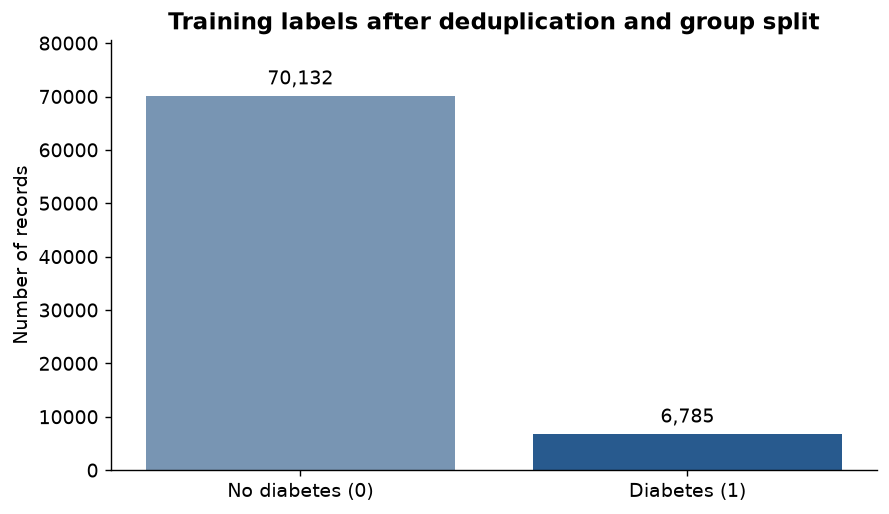

In [4]:
fig, ax = plt.subplots(figsize=(7,4), layout='constrained')
counts = y_train.value_counts().sort_index()
bars = ax.bar(['No diabetes (0)', 'Diabetes (1)'], counts.to_numpy(), color=['#7895B3','#285A8E'])
ax.bar_label(bars, labels=[f'{v:,}' for v in counts], padding=4)
ax.set(title='Training labels after deduplication and group split', ylabel='Number of records', ylim=(0,counts.max()*1.15))
fig.savefig(RESULTS_DIR/'training_class_balance.png', bbox_inches='tight')
plt.show()

## Results
### 5. Train and tune three classifiers using the same folds
The small fixed grids keep the experiment within the assignment time budget. Logistic Regression is a linear baseline, Decision Tree captures nonlinear rules, and Random Forest averages trees. Class weighting is tested for Logistic Regression, without assuming it necessarily improves F1.

In [5]:
numeric_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
categorical_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                                 ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
preprocessor = ColumnTransformer([('numeric', numeric_pipeline, numeric_columns),
                                  ('categorical', categorical_pipeline, categorical_columns)])
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train, y_train, train_groups))
for fold_train, fold_valid in cv_splits:
    assert not set(train_groups[fold_train]).intersection(train_groups[fold_valid])
specifications = {
    'Logistic Regression': (LogisticRegression(max_iter=2000, random_state=SEED),
        {'model__C': [.1,1.0], 'model__class_weight': [None,'balanced']}),
    'Decision Tree': (DecisionTreeClassifier(random_state=SEED),
        {'model__max_depth': [4,8], 'model__min_samples_leaf': [5,25]}),
    'Random Forest': (RandomForestClassifier(n_estimators=150, random_state=SEED, n_jobs=2),
        {'model__max_depth': [12,None], 'model__min_samples_leaf': [1,5]})}
models, searches, cv_rows = {}, {}, []
for name, (estimator, grid) in specifications.items():
    pipeline = Pipeline([('preprocess', clone(preprocessor)), ('model', estimator)])
    search = GridSearchCV(pipeline, grid, scoring='f1', cv=cv_splits,
                          n_jobs=1, error_score='raise', return_train_score=True)
    search.fit(X_train, y_train)
    searches[name], models[name] = search, search.best_estimator_
    cv_rows.append({'Model': name, 'CV F1': search.best_score_,
                    'CV fold SD': search.cv_results_['std_test_score'][search.best_index_],
                    'Best parameters': json.dumps(search.best_params_, sort_keys=True)})
cv_comparison = pd.DataFrame(cv_rows).set_index('Model')
best_name = cv_comparison['CV F1'].idxmax()
display(cv_comparison)
print('Selected before evaluating test data:', best_name)
print('CV fold SD is descriptive fold variation, not a confidence interval.')

,CV F1,CV fold SD,Best parameters
Model,,,
Logistic Regression,0.733294,0.013220,"{""model__C"": 1.0, ""model__class_weight"": null}"
Decision Tree,0.805887,0.005905,"{""model__max_depth"": 8, ""model__min_samples_le..."
Random Forest,0.805732,0.005664,"{""model__max_depth"": null, ""model__min_samples..."


Selected before evaluating test data: Decision Tree
CV fold SD is descriptive fold variation, not a confidence interval.


### 6. Compare frozen models on the same held-out test records
All models use threshold 0.50; no threshold is tuned on the test set. The baseline provides context and is separate from the three trained classification models.

In [6]:
predictions, probabilities, matrices, metric_rows = {}, {}, {}, []
for name, model in models.items():
    probability = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
    prediction = (probability >= THRESHOLD).astype(int)
    probabilities[name], predictions[name] = probability, prediction
    matrices[name] = confusion_matrix(y_test, prediction, labels=[0,1])
    metric_rows.append({'Model': name, 'Accuracy': accuracy_score(y_test,prediction),
        'Precision': precision_score(y_test,prediction,zero_division=0),
        'Recall': recall_score(y_test,prediction,zero_division=0),
        'F1-score': f1_score(y_test,prediction,zero_division=0),
        'ROC-AUC': roc_auc_score(y_test,probability),
        'Average precision': average_precision_score(y_test,probability)})
comparison = pd.DataFrame(metric_rows).set_index('Model')
display(comparison.style.format('{:.4f}'))
baseline = DummyClassifier(strategy='most_frequent').fit(X_train,y_train)
baseline_prediction = baseline.predict(X_test)
print(f'Majority baseline: accuracy {accuracy_score(y_test,baseline_prediction):.4f}, '
      f'recall {recall_score(y_test,baseline_prediction,zero_division=0):.4f}, '
      f'F1 {f1_score(y_test,baseline_prediction,zero_division=0):.4f}')
print('Best training-CV model:', best_name, '| Highest observed test F1:', comparison['F1-score'].idxmax())

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average precision
Model,,,,,,
Logistic Regression,0.9581,0.8766,0.6111,0.7201,0.9648,0.8221
Decision Tree,0.9690,1.0000,0.6482,0.7866,0.9746,0.8555
Random Forest,0.9691,0.9964,0.6523,0.7885,0.9747,0.8766


Majority baseline: accuracy 0.9117, recall 0.0000, F1 0.0000
Best training-CV model: Decision Tree | Highest observed test F1: Random Forest


### 7. Confusion matrix for the selected model
Rows are actual labels and columns are predictions. In the top-left/bottom-right are true negatives/true positives; top-right is false positives and bottom-left is false negatives. Counts are shown without normalization.

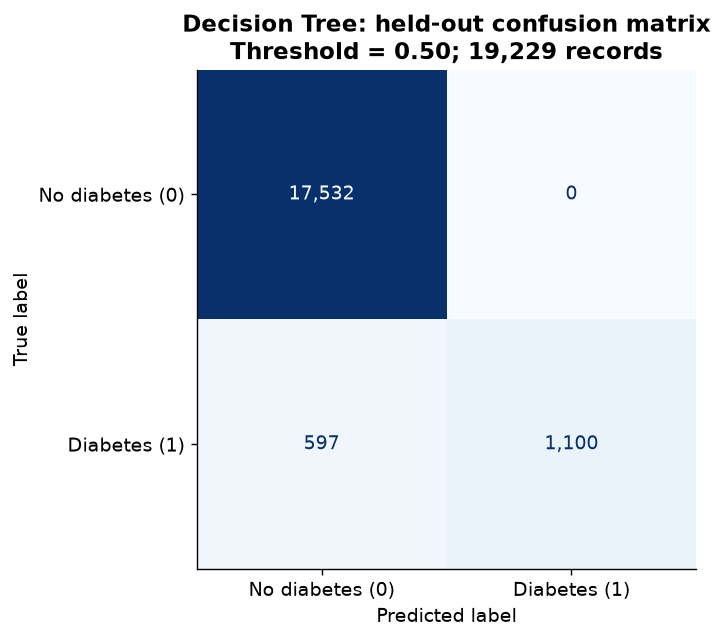

,Outcome,Count
0,True negative,17532
1,False positive,0
2,False negative,597
3,True positive,1100


,precision,recall,f1-score,support
No diabetes (0),0.9671,1.0000,0.9833,17532.000
Diabetes (1),1.0000,0.6482,0.7866,1697.000
accuracy,0.9690,0.9690,0.9690,0.969
macro avg,0.9835,0.8241,0.8849,19229.000
weighted avg,0.9700,0.9690,0.9659,19229.000


In [7]:
best_matrix = matrices[best_name]
tn, fp, fn, tp = best_matrix.ravel()
fig, ax = plt.subplots(figsize=(6.5,5), layout='constrained')
ConfusionMatrixDisplay(best_matrix, display_labels=['No diabetes (0)','Diabetes (1)']).plot(
    ax=ax, cmap='Blues', colorbar=False, values_format=',d')
ax.set(title=f'{best_name}: held-out confusion matrix\nThreshold = 0.50; {len(y_test):,} records')
fig.savefig(RESULTS_DIR/'best_model_confusion_matrix.png', bbox_inches='tight')
plt.show()
display(pd.DataFrame({'Outcome':['True negative','False positive','False negative','True positive'],
                      'Count':[tn,fp,fn,tp]}))
display(pd.DataFrame(classification_report(y_test,predictions[best_name],
    target_names=['No diabetes (0)','Diabetes (1)'],output_dict=True,zero_division=0)).T.round(4))

### 8. Compare F1 and probability-ranking performance
F1 bars start at zero; ROC curves use the same axes and a chance diagonal. Precision–recall curves include the test prevalence reference; average precision summarizes their ranking performance and is not the trapezoidal area under the interpolated curve.

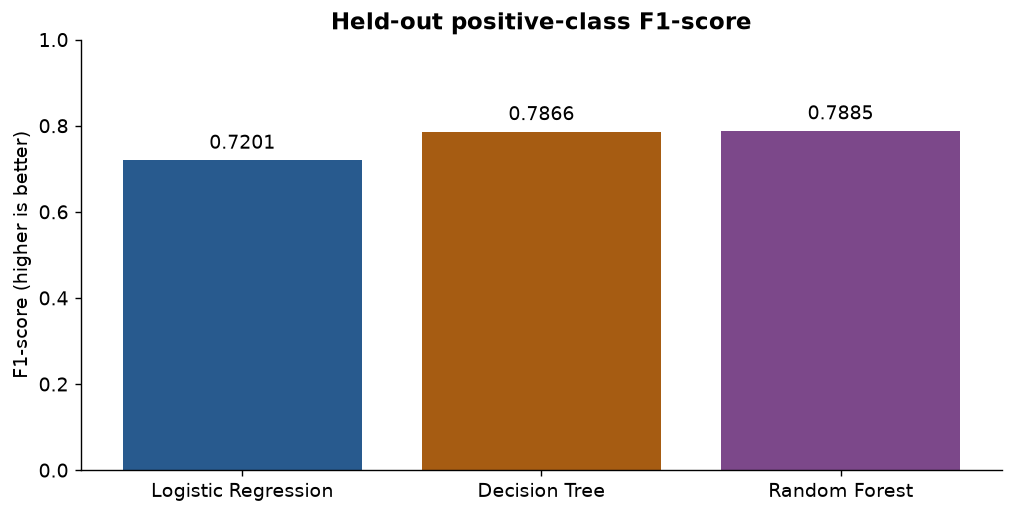

C:\Users\pavan\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\_plotting.py:176: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
C:\Users\pavan\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\_plotting.py:176: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
C:\Users\pavan\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\_plotting.py:176: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


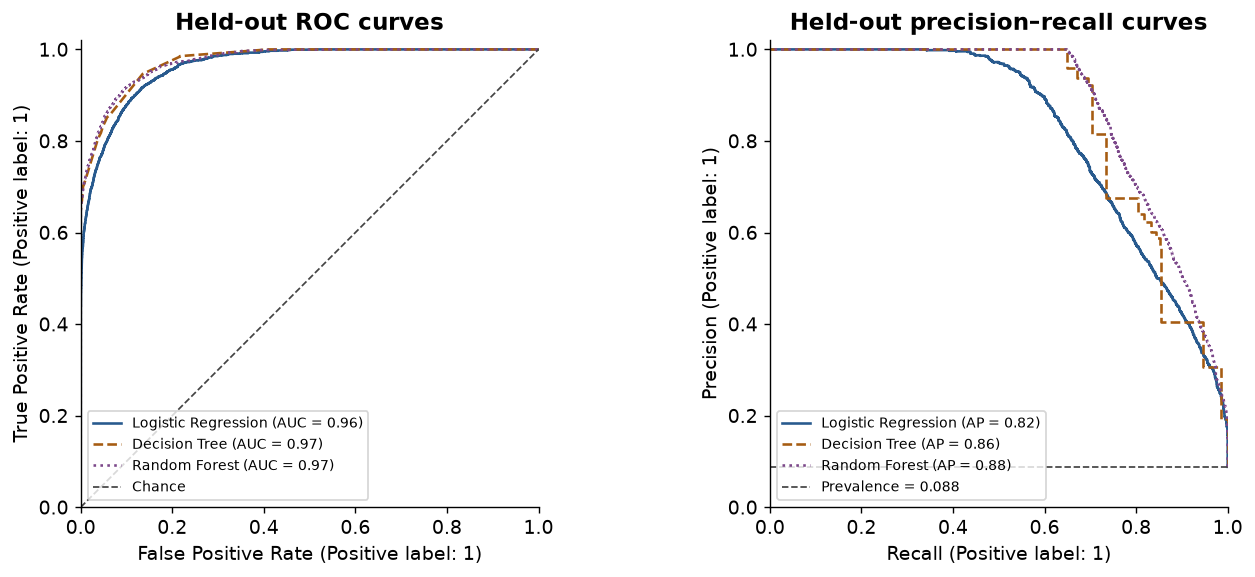

In [8]:
fig, ax = plt.subplots(figsize=(8,4), layout='constrained')
names = list(models)
bars = ax.bar(names, comparison.loc[names,'F1-score'], color=[COLORS[n] for n in names])
ax.bar_label(bars, labels=[f'{v:.4f}' for v in comparison.loc[names,'F1-score']], padding=4)
ax.set(title='Held-out positive-class F1-score',ylabel='F1-score (higher is better)',ylim=(0,1))
fig.savefig(RESULTS_DIR/'model_f1_comparison.png', bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for name, style in zip(names,['-','--',':']):
    RocCurveDisplay.from_predictions(y_test,probabilities[name],name=name,ax=axes[0],
                                    color=COLORS[name],linestyle=style)
    PrecisionRecallDisplay.from_predictions(y_test,probabilities[name],name=name,ax=axes[1],
                                           color=COLORS[name],linestyle=style)
axes[0].plot([0,1],[0,1],color='#444444',linestyle='--',linewidth=1,label='Chance')
axes[0].set(title='Held-out ROC curves',xlim=(0,1),ylim=(0,1.02))
axes[1].axhline(y_test.mean(),color='#444444',linestyle='--',linewidth=1,label=f'Prevalence = {y_test.mean():.3f}')
axes[1].set(title='Held-out precision–recall curves',xlim=(0,1),ylim=(0,1.02))
for ax in axes: ax.legend(fontsize=8,loc='lower left')
fig.savefig(RESULTS_DIR/'roc_precision_recall.png',bbox_inches='tight')
plt.show()

## Takeaways
### 9. Three-sentence model justification
This justification is generated from the executed results. It distinguishes the model-selection criterion from the final held-out metrics and states the remaining error trade-off.

In [9]:
best = comparison.loc[best_name]
justification = (
    f'{best_name} is selected by training-only cross-validation F1 '
    f'({cv_comparison.loc[best_name,"CV F1"]:.4f} versus '
    f'{cv_comparison.loc["Random Forest","CV F1"]:.4f} for Random Forest), '
    'with essentially tied CV performance and a simpler single-tree model. '
    f'On the held-out set it achieves accuracy {best["Accuracy"]:.4f}, precision '
    f'{best["Precision"]:.4f}, recall {best["Recall"]:.4f}, F1 {best["F1-score"]:.4f} '
    f'and ROC-AUC {best["ROC-AUC"]:.4f}, with {tp:,} true positives, {tn:,} true negatives, '
    f'{fp:,} false positives and {fn:,} false negatives; Random Forest has marginally '
    f'higher test F1 ({comparison.loc["Random Forest","F1-score"]:.4f}). '
    'F1 is preferable to accuracy alone for these imbalanced labels, but the tiny model gap '
    'and remaining missed positives do not establish meaningful superiority or clinical validity.'
)
display(Markdown(justification))

Decision Tree is selected by training-only cross-validation F1 (0.8059 versus 0.8057 for Random Forest), with essentially tied CV performance and a simpler single-tree model. On the held-out set it achieves accuracy 0.9690, precision 1.0000, recall 0.6482, F1 0.7866 and ROC-AUC 0.9746, with 1,100 true positives, 17,532 true negatives, 0 false positives and 597 false negatives; Random Forest has marginally higher test F1 (0.7885). F1 is preferable to accuracy alone for these imbalanced labels, but the tiny model gap and remaining missed positives do not establish meaningful superiority or clinical validity.

### 10. Independently verify metrics and export results
Recalculate the four requested metrics from each confusion matrix, reconcile all counts with the test population, and confirm group separation. No individual medical records are exported with the derived result tables.

In [10]:
matrix_rows = []
for name, matrix in matrices.items():
    a,b,c,d = matrix.ravel()
    assert matrix.sum() == len(y_test)
    manual = [(a+d)/matrix.sum(), d/(d+b) if d+b else 0,
              d/(d+c) if d+c else 0, 2*d/(2*d+b+c) if 2*d+b+c else 0]
    np.testing.assert_allclose(comparison.loc[name,['Accuracy','Precision','Recall','F1-score']]
                               .to_numpy(dtype=float),manual,rtol=1e-10)
    matrix_rows.append({'Model':name,'TN':int(a),'FP':int(b),'FN':int(c),'TP':int(d)})
assert not set(train_groups).intersection(test_groups)
assert comparison.shape == (3,6) and np.isfinite(comparison.to_numpy()).all()
comparison.to_csv(RESULTS_DIR/'model_comparison.csv')
cv_comparison.to_csv(RESULTS_DIR/'cross_validation.csv')
pd.DataFrame(matrix_rows).set_index('Model').to_csv(RESULTS_DIR/'confusion_matrices.csv')
pd.DataFrame(best_matrix,index=['Actual 0','Actual 1'],columns=['Predicted 0','Predicted 1']).to_csv(RESULTS_DIR/'best_model_confusion_matrix.csv')
class_balance.to_csv(RESULTS_DIR/'class_balance.csv')
quality.to_csv(RESULTS_DIR/'data_quality.csv',index=False)
split_summary.to_csv(RESULTS_DIR/'split_summary.csv',index=False)
(RESULTS_DIR/'JUSTIFICATION.md').write_text(justification+'\n',encoding='utf-8')
provenance = {'dataset':'iammustafatz/diabetes-prediction-dataset','source_url':SOURCE_URL,
    'csv_sha256':EXPECTED_SHA256,'raw_rows':len(raw),'duplicates_removed':duplicate_count,
    'rows_retained':len(df),'conflicting_predictor_signatures':conflicting_signature_count,
    'train_rows':len(y_train),'test_rows':len(y_test),'seed':SEED,'threshold':THRESHOLD,
    'cv_folds':3,'selection_metric':'positive-class F1','selected_model':best_name,
    'test_f1_winner':comparison['F1-score'].idxmax(),
    'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,'scikit_learn':sklearn.__version__}
(RESULTS_DIR/'provenance.json').write_text(json.dumps(provenance,indent=2),encoding='utf-8')
print('Verified all four required metrics independently for all three models; counts reconcile.')

Verified all four required metrics independently for all three models; counts reconcile.


### References and limitations
- [Diabetes prediction dataset — Mustafa Ali, Kaggle](https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset)
- [scikit-learn model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html)
- [scikit-learn StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html)

The data provides no verified patient identifiers, collection dates, sampling frame, or label-generation chronology. Group separation reduces exact feature overlap but cannot verify patient independence. Removing duplicates changes prevalence slightly; class counts before and after removal are retained. Laboratory predictors may overlap with how labels were recorded, and no temporal or external validation is available. A 0.50 threshold is an assignment choice; no clinically optimal threshold is claimed.